# Obtención de Datos Mediante APIs en Python

Alguna de las formas de obtención de datos es a través de **APIs (Application Programming Interfaces)**. Las APIs son una forma eficiente de acceder a datos y servicios en línea. Aprenderemos a realizar solicitudes a través de Python utilizando la popular biblioteca `requests`.

## Introducción a las APIs

Una API (Application Programming Interface) es un conjunto de reglas y protocolos que permiten a diferentes aplicaciones interactuar entre sí. Las APIs permiten a las aplicaciones solicitar datos o realizar acciones en un servidor remoto de manera estructurada y estandarizada.

![imagen](./img/http.PNG)

## Protocolo HTTP

El Protocolo de Transferencia de Hipertexto (HTTP) es el protocolo subyacente utilizado en la World Wide Web. Se utiliza para solicitar y transmitir datos en la web. 

![imagen](./img/peticion_respuesta.PNG)

Aquí tienes un ejemplo de arquitectura:

![imagen](./img/arquitectura_servidor.PNG)

Las solicitudes HTTP se pueden realizar utilizando varios métodos, siendo los más comunes:

* **GET**: Para recuperar datos.
* **POST**: Para enviar datos al servidor.
* **PUT**: Para actualizar datos en el servidor.
* **DELETE**: Para eliminar datos en el servidor.


![imagen](./img/documentacion_api.PNG)

Podemos hacer una petición:

![imagen](./img/parametros.PNG)

y obtener como respuesta diferentes códigos:

![imagen](./img/status_codes.PNG)

Ejemplo de la API de Marvel. La URL se construye como *urlbase* + *endpoint* + *params*

En general para acceder a un servicio de una API la URL se construye como *urlbase* + *endpoint* + *params*

![imagen](./img/MarvelAccessPoints.png)

## Biblioteca ``requests``

La biblioteca requests es una de las más populares para realizar solicitudes HTTP en Python. Permite enviar solicitudes y procesar respuestas de una manera sencilla y eficiente.

In [ ]:
%pip install requests

Note: you may need to restart the kernel to use updated packages.


In [1]:
# Importamos librerias
import io
import requests
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

## Primera petición

In [2]:
url = "https://pbs.twimg.com/profile_images/616689518968762368/rkhjKqNb.jpg"
image = requests.get(url)

In [3]:
image


<Response [200]>

In [4]:
image.content

b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00\xff\xe2\x02\xa0ICC_PROFILE\x00\x01\x01\x00\x00\x02\x90lcms\x040\x00\x00mntrRGB XYZ \x07\xdf\x00\x07\x00\x02\x00\x13\x00\x1a\x005acspAPPL\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\xf6\xd6\x00\x01\x00\x00\x00\x00\xd3-lcms\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x0bdesc\x00\x00\x01\x08\x00\x00\x008cprt\x00\x00\x01@\x00\x00\x00Nwtpt\x00\x00\x01\x90\x00\x00\x00\x14chad\x00\x00\x01\xa4\x00\x00\x00,rXYZ\x00\x00\x01\xd0\x00\x00\x00\x14bXYZ\x00\x00\x01\xe4\x00\x00\x00\x14gXYZ\x00\x00\x01\xf8\x00\x00\x00\x14rTRC\x00\x00\x02\x0c\x00\x00\x00 gTRC\x00\x00\x02,\x00\x00\x00 bTRC\x00\x00\x02L\x00\x00\x00 chrm\x00\x00\x02l\x00\x00\x00$mluc\x00\x00\x00\x00\x00\x00\x00\x01\x00\x00\x00\x0cenUS\x00\x00\x00\x1c\x00\x00\x00\x1c\x00s

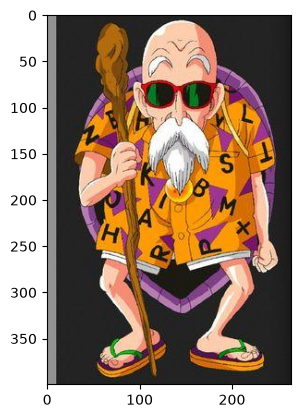

In [5]:
plt.imshow(Image.open(io.BytesIO(image.content)));

### Mediante pandas

In [6]:
df_inflation = pd.read_csv('https://datahub.io/core/inflation/r/inflation-gdp.csv')
df_inflation.head()

,Country,Country Code,Year,Inflation
0,Aruba,ABW,1985,4.032258
1,Aruba,ABW,1986,1.073966
2,Aruba,ABW,1987,3.643045
3,Aruba,ABW,1988,3.121868
4,Aruba,ABW,1989,3.991628


In [7]:
df_inflation[df_inflation['Country'] == "Spain"]

,Country,Country Code,Year,Inflation
2904,Spain,ESP,1960,1.177771
2905,Spain,ESP,1961,0.809253
2906,Spain,ESP,1962,5.706477
2907,Spain,ESP,1963,8.743698
2908,Spain,ESP,1964,6.979247
...,...,...,...,...
2964,Spain,ESP,2020,-0.322753
2965,Spain,ESP,2021,3.093135
2966,Spain,ESP,2022,8.390576
2967,Spain,ESP,2023,3.532361


## Bajar datos de Bicimad

In [42]:
url = 'https://opendata.emtmadrid.es/getattachment/c3383795-121b-4ebf-98b4-c7b05e902eaf/202106_movements.aspx'

r = requests.get(url)

In [9]:
# url = 'https://datos.emtmadrid.es/dataset/a3442c30-ee33-434f-998d-c63a51a8c446/resource/883ba442-76f4-4969-b5b2-1e9d50df2f86/download/bicimadviajesdia.csv'
url = 'https://media.emtmadrid.es/-BRk4rTaAdV'
r = requests.get(url)

In [10]:
r

<Response [200]>

In [11]:
r.content

: 

: 

In [8]:
# Guardamos el zip
filename = 'data/bicis_new.zip'
with open(filename, 'wb') as f:
   f.write(r.content)

NameError: name 'r' is not defined

In [17]:
# Extraemos lo que hay dentro
filename = './data/bicis.zip'
with zipfile.ZipFile(filename, 'r') as zip_ref:
    zip_ref.extractall("data/")

In [52]:
## Leemos los datos
datos_bicis = pd.read_csv('data/bicis_new.csv') #, lines=True, encoding='latin-1', nrows=10000)

In [53]:
# Vemos qué pinta tienen
datos_bicis.head()

,FECHA;VIAJES
0,2024-02-01;26194
1,2024-02-02;24706
2,2024-02-03;21059
3,2024-02-04;19990
4,2024-02-05;21616


In [54]:
datos_bicis.info()

<class 'pandas.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 1 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   FECHA;VIAJES  973 non-null    str  
dtypes: str(1)
memory usage: 7.7 KB


In [55]:
datos_bicis['zip_code'].unique()

KeyError: 'zip_code'

## Api chucknorris

[Enlace API](https://api.chucknorris.io/)

In [27]:
url = "https://api.chucknorris.io/jokes/random"  # Reemplaza con la URL de la API que deseas acceder.

response = requests.get(url)
response.json()
if response.status_code == 200:  # Código 200 indica una respuesta exitosa.
    data = response.json()  # Analizar la respuesta JSON.
    #print(data["value"])
    print(data)
else:
    print("Error en la solicitud: ", response.status_code)
data["value"]

{'categories': [], 'created_at': '2020-01-05 13:42:26.766831', 'icon_url': 'https://api.chucknorris.io/img/avatar/chuck-norris.png', 'id': '41b6Lmt6QCqFtdQbMhjhYQ', 'updated_at': '2020-01-05 13:42:26.766831', 'url': 'https://api.chucknorris.io/jokes/41b6Lmt6QCqFtdQbMhjhYQ', 'value': "Chuck Norris wouldn't do anything for love. Love would do anything for Chuck Norris."}


"Chuck Norris wouldn't do anything for love. Love would do anything for Chuck Norris."

In [28]:
def get_joke(url):
    response = requests.get(url)

    if response.status_code == 200:  # Código 200 indica una respuesta exitosa.
        data = response.json()  # Analizar la respuesta JSON.
        return data
    else:
        print("Error en la solicitud: ", response.status_code)

In [29]:
url = "https://api.chucknorris.io/jokes/categories"
get_joke(url)

['animal',
 'career',
 'celebrity',
 'dev',
 'explicit',
 'fashion',
 'food',
 'history',
 'money',
 'movie',
 'music',
 'political',
 'religion',
 'science',
 'sport',
 'travel']

In [30]:
url = "https://api.chucknorris.io/jokes/random?category=animal"
get_joke(url)

{'categories': ['animal'],
 'created_at': '2020-01-05 13:42:19.576875',
 'icon_url': 'https://api.chucknorris.io/img/avatar/chuck-norris.png',
 'id': 'bmom6jqftpqgokh8adtolw',
 'updated_at': '2020-01-05 13:42:19.576875',
 'url': 'https://api.chucknorris.io/jokes/bmom6jqftpqgokh8adtolw',
 'value': 'Chuck Norris once rode a nine foot grizzly bear through an automatic car wash, instead of taking a shower.'}

In [31]:
joke = get_joke(url)
joke["value"]

'Chuck Norris once rode a bull, and nine months later it had a calf.'

### POST
Nota: REQUIERE API KEY

In [28]:
# URL de la API de prueba
url = "https://reqres.in/api/users"

# Datos a enviar en el request
data = {
    "name": "Juan Pérez",
    "job": "Científico de Datos"
}

# Enviar solicitud POST
response = requests.post(url, json=data)

# Verificar la respuesta
if response.status_code == 201:  # Código 201 = Creado exitosamente
    print("Usuario creado con éxito.")
    print("Respuesta de la API:", response.json())  # Mostrar datos devueltos
else:
    print("Error en la solicitud:", response.status_code)

Error en la solicitud: 403


## Datos del espacio

In [2]:
'''
https://thespacedevs.com/llapi
https://ll.thespacedevs.com/2.2.0/swagger
'''
space_url = "http://ll.thespacedevs.com/2.2.0"

path = "/astronaut"

url_total = space_url + path #+ "/?limit=20"

response = requests.get(url_total)

In [3]:
print(url_total)

http://ll.thespacedevs.com/2.2.0/astronaut


In [4]:
print(response.status_code)
#type(response.content)
#response.json()

522


In [5]:
type(response.content)


bytes

In [6]:
astronautas = response.json()
astronautas

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [37]:
astronautas["results"][0]["name"]

'Thomas Pesquet'

In [38]:
astronautas["results"][0]["status"]["name"]

'Active'

In [ ]:
#pd.DataFrame(astronautas["results"])

In [39]:
astronautas["results"][0]["agency"]["type"]

'Multinational'

In [40]:
for astronauta in astronautas["results"]:
    print(astronauta)

{'id': 1, 'url': 'https://ll.thespacedevs.com/2.2.0/astronaut/1/', 'name': 'Thomas Pesquet', 'status': {'id': 1, 'name': 'Active'}, 'type': {'id': 2, 'name': 'Government'}, 'in_space': False, 'time_in_space': 'P396DT11H33M45S', 'eva_time': 'P1DT15H54M', 'age': 48, 'date_of_birth': '1978-02-27', 'date_of_death': None, 'nationality': 'French', 'bio': 'Thomas Gautier Pesquet is a French aerospace engineer, pilot, and European Space Agency astronaut. Pesquet was selected by ESA as a candidate in May 2009, and he successfully completed his basic training in November 2010. From November 2016 to June 2017, Pesquet was part of Expeditions 50 and 51 on the International Space Station as a flight engineer.', 'twitter': 'https://twitter.com/Thom_astro', 'instagram': 'https://instagram.com/thom_astro', 'wiki': 'https://en.wikipedia.org/wiki/Thomas_Pesquet', 'agency': {'id': 27, 'url': 'https://ll.thespacedevs.com/2.2.0/agencies/27/', 'name': 'European Space Agency', 'featured': False, 'type': 'Mul

In [41]:

astro_dict = {
    "name":[],
    "status":[],
    "type":[]
}

for astronauta in astronautas["results"]:
    #print(astronauta["name"])
    #print(astronauta["status"]["name"])
    #print(astronauta["agency"]["type"])
    #print()
    astro_dict["name"].append(astronauta["name"])
    astro_dict["status"].append(astronauta["status"]["name"])
    astro_dict["type"].append(astronauta["agency"]["type"])
    
astro_dict
  

{'name': ['Thomas Pesquet',
  'Claude Nicollier',
  'Tim Peake',
  'Buzz Aldrin',
  'Chris Hadfield',
  'David Saint-Jacques',
  'Anne McClain',
  'Andrew R. Morgan',
  'Nick Hague',
  'Terry W. Virts'],
 'status': ['Active',
  'Retired',
  'Retired',
  'Retired',
  'Retired',
  'Active',
  'Active',
  'Active',
  'Retired',
  'Retired'],
 'type': ['Multinational',
  'Multinational',
  'Multinational',
  'Government',
  'Government',
  'Government',
  'Government',
  'Government',
  'Government',
  'Government']}

In [42]:
astrodf = pd.DataFrame(astro_dict)
astrodf

,name,status,type
0,Thomas Pesquet,Active,Multinational
1,Claude Nicollier,Retired,Multinational
2,Tim Peake,Retired,Multinational
3,Buzz Aldrin,Retired,Government
4,Chris Hadfield,Retired,Government
5,David Saint-Jacques,Active,Government
6,Anne McClain,Active,Government
7,Andrew R. Morgan,Active,Government
8,Nick Hague,Retired,Government
9,Terry W. Virts,Retired,Government


In [43]:
url_total

'http://ll.thespacedevs.com/2.2.0/astronaut'

In [44]:
url_total = space_url + path + "/?age=45"

response_sp = requests.get(url_total)

In [45]:
response_sp

<Response [200]>

In [48]:
url_total

'http://ll.thespacedevs.com/2.2.0/astronaut/?age=45'

In [46]:
response_sp.json()

{'count': 6,
 'next': None,
 'previous': None,
 'results': [{'id': 152,
   'url': 'https://ll.thespacedevs.com/2.2.0/astronaut/152/',
   'name': 'Rick Husband',
   'status': {'id': 4, 'name': 'Lost In Flight'},
   'type': {'id': 2, 'name': 'Government'},
   'in_space': False,
   'time_in_space': 'P25DT17H32M18S',
   'eva_time': 'P0D',
   'age': 45,
   'date_of_birth': '1957-07-12',
   'date_of_death': '2003-02-01',
   'nationality': 'American',
   'bio': "Rick Douglas Husband (July 12, 1957 – February 1, 2003) (Colonel, USAF) was an American astronaut and fighter pilot. He traveled into space twice: as Pilot of STS-96 and Commander of STS-107. He and the rest of the crew of STS-107 were killed when Columbia disintegrated during reentry into the Earth's atmosphere.",
   'twitter': None,
   'instagram': None,
   'wiki': 'https://en.wikipedia.org/wiki/Rick_Husband',
   'agency': {'id': 44,
    'url': 'https://ll.thespacedevs.com/2.2.0/agencies/44/',
    'name': 'National Aeronautics and S

In [47]:
response_sp.json()['results']

[{'id': 152,
  'url': 'https://ll.thespacedevs.com/2.2.0/astronaut/152/',
  'name': 'Rick Husband',
  'status': {'id': 4, 'name': 'Lost In Flight'},
  'type': {'id': 2, 'name': 'Government'},
  'in_space': False,
  'time_in_space': 'P25DT17H32M18S',
  'eva_time': 'P0D',
  'age': 45,
  'date_of_birth': '1957-07-12',
  'date_of_death': '2003-02-01',
  'nationality': 'American',
  'bio': "Rick Douglas Husband (July 12, 1957 – February 1, 2003) (Colonel, USAF) was an American astronaut and fighter pilot. He traveled into space twice: as Pilot of STS-96 and Commander of STS-107. He and the rest of the crew of STS-107 were killed when Columbia disintegrated during reentry into the Earth's atmosphere.",
  'twitter': None,
  'instagram': None,
  'wiki': 'https://en.wikipedia.org/wiki/Rick_Husband',
  'agency': {'id': 44,
   'url': 'https://ll.thespacedevs.com/2.2.0/agencies/44/',
   'name': 'National Aeronautics and Space Administration',
   'featured': True,
   'type': 'Government',
   'count

In [49]:
results = response_sp.json()['results']
len(results)

6

In [50]:
type(results)

list

In [51]:
results[0]

{'id': 152,
 'url': 'https://ll.thespacedevs.com/2.2.0/astronaut/152/',
 'name': 'Rick Husband',
 'status': {'id': 4, 'name': 'Lost In Flight'},
 'type': {'id': 2, 'name': 'Government'},
 'in_space': False,
 'time_in_space': 'P25DT17H32M18S',
 'eva_time': 'P0D',
 'age': 45,
 'date_of_birth': '1957-07-12',
 'date_of_death': '2003-02-01',
 'nationality': 'American',
 'bio': "Rick Douglas Husband (July 12, 1957 – February 1, 2003) (Colonel, USAF) was an American astronaut and fighter pilot. He traveled into space twice: as Pilot of STS-96 and Commander of STS-107. He and the rest of the crew of STS-107 were killed when Columbia disintegrated during reentry into the Earth's atmosphere.",
 'twitter': None,
 'instagram': None,
 'wiki': 'https://en.wikipedia.org/wiki/Rick_Husband',
 'agency': {'id': 44,
  'url': 'https://ll.thespacedevs.com/2.2.0/agencies/44/',
  'name': 'National Aeronautics and Space Administration',
  'featured': True,
  'type': 'Government',
  'country_code': 'USA',
  'ab

In [52]:
pd.DataFrame(response_sp.json()['results'])

,id,url,name,status,type,in_space,time_in_space,eva_time,age,date_of_birth,...,instagram,wiki,agency,profile_image,profile_image_thumbnail,flights_count,landings_count,spacewalks_count,last_flight,first_flight
0,152,https://ll.thespacedevs.com/2.2.0/astronaut/152/,Rick Husband,"{'id': 4, 'name': 'Lost In Flight'}","{'id': 2, 'name': 'Government'}",False,P25DT17H32M18S,P0D,45,1957-07-12,...,NaN,https://en.wikipedia.org/wiki/Rick_Husband,"{'id': 44, 'url': 'https://ll.thespacedevs.com...",https://thespacedevs-prod.nyc3.digitaloceanspa...,https://thespacedevs-prod.nyc3.digitaloceanspa...,2,2,0,2003-01-16T15:39:00Z,1999-05-27T10:49:42Z
1,648,https://ll.thespacedevs.com/2.2.0/astronaut/648/,Joseph A. Walker,"{'id': 11, 'name': 'Deceased'}","{'id': 2, 'name': 'Government'}",False,PT2H32M32S,P0D,45,1921-02-20,...,NaN,https://en.wikipedia.org/wiki/Joseph_A._Walker,"{'id': 44, 'url': 'https://ll.thespacedevs.com...",https://thespacedevs-prod.nyc3.digitaloceanspa...,https://thespacedevs-prod.nyc3.digitaloceanspa...,3,3,0,1963-08-22T18:05:57Z,1963-01-17T16:59:00Z
2,666,https://ll.thespacedevs.com/2.2.0/astronaut/666/,Ye Guangfu,"{'id': 1, 'name': 'Active'}","{'id': 2, 'name': 'Government'}",False,P374DT13H58M8S,PT21H5M,45,1980-09-01,...,NaN,https://en.wikipedia.org/wiki/Ye_Guangfu,"{'id': 17, 'url': 'https://ll.thespacedevs.com...",https://thespacedevs-prod.nyc3.digitaloceanspa...,https://thespacedevs-prod.nyc3.digitaloceanspa...,2,2,3,2024-04-25T12:59:00Z,2021-10-15T16:23:56Z
3,680,https://ll.thespacedevs.com/2.2.0/astronaut/680/,Beth Moses,"{'id': 1, 'name': 'Active'}","{'id': 3, 'name': 'Private'}",False,PT1H25M55S,P0D,45,1980-05-30,...,NaN,https://en.wikipedia.org/wiki/Beth_Moses,"{'id': 1024, 'url': 'https://ll.thespacedevs.c...",https://thespacedevs-prod.nyc3.digitaloceanspa...,https://thespacedevs-prod.nyc3.digitaloceanspa...,5,5,0,2023-10-06T16:10:30Z,2019-02-22T16:57:00Z
4,732,https://ll.thespacedevs.com/2.2.0/astronaut/732/,Andrei Fedyaev,"{'id': 1, 'name': 'Active'}","{'id': 2, 'name': 'Government'}",True,P223DT15H49M37S,P0D,45,1981-02-26,...,NaN,https://en.wikipedia.org/wiki/Andrey_Fedyaev,"{'id': 63, 'url': 'https://ll.thespacedevs.com...",https://thespacedevs-prod.nyc3.digitaloceanspa...,https://thespacedevs-prod.nyc3.digitaloceanspa...,2,1,0,2026-02-13T10:15:56Z,2023-03-02T05:34:14Z
5,774,https://ll.thespacedevs.com/2.2.0/astronaut/774/,Marcus Wandt,"{'id': 1, 'name': 'Active'}","{'id': 2, 'name': 'Government'}",False,P21DT15H40M49S,P0D,45,1980-09-22,...,https://www.instagram.com/esaastro_marcus/,https://en.wikipedia.org/wiki/Marcus_Wandt,"{'id': 27, 'url': 'https://ll.thespacedevs.com...",https://thespacedevs-prod.nyc3.digitaloceanspa...,https://thespacedevs-prod.nyc3.digitaloceanspa...,1,1,0,2024-01-18T21:49:11Z,2024-01-18T21:49:11Z


In [53]:
response_sp.json()

{'count': 6,
 'next': None,
 'previous': None,
 'results': [{'id': 152,
   'url': 'https://ll.thespacedevs.com/2.2.0/astronaut/152/',
   'name': 'Rick Husband',
   'status': {'id': 4, 'name': 'Lost In Flight'},
   'type': {'id': 2, 'name': 'Government'},
   'in_space': False,
   'time_in_space': 'P25DT17H32M18S',
   'eva_time': 'P0D',
   'age': 45,
   'date_of_birth': '1957-07-12',
   'date_of_death': '2003-02-01',
   'nationality': 'American',
   'bio': "Rick Douglas Husband (July 12, 1957 – February 1, 2003) (Colonel, USAF) was an American astronaut and fighter pilot. He traveled into space twice: as Pilot of STS-96 and Commander of STS-107. He and the rest of the crew of STS-107 were killed when Columbia disintegrated during reentry into the Earth's atmosphere.",
   'twitter': None,
   'instagram': None,
   'wiki': 'https://en.wikipedia.org/wiki/Rick_Husband',
   'agency': {'id': 44,
    'url': 'https://ll.thespacedevs.com/2.2.0/agencies/44/',
    'name': 'National Aeronautics and S

In [54]:
response_sp.json()['results']

[{'id': 152,
  'url': 'https://ll.thespacedevs.com/2.2.0/astronaut/152/',
  'name': 'Rick Husband',
  'status': {'id': 4, 'name': 'Lost In Flight'},
  'type': {'id': 2, 'name': 'Government'},
  'in_space': False,
  'time_in_space': 'P25DT17H32M18S',
  'eva_time': 'P0D',
  'age': 45,
  'date_of_birth': '1957-07-12',
  'date_of_death': '2003-02-01',
  'nationality': 'American',
  'bio': "Rick Douglas Husband (July 12, 1957 – February 1, 2003) (Colonel, USAF) was an American astronaut and fighter pilot. He traveled into space twice: as Pilot of STS-96 and Commander of STS-107. He and the rest of the crew of STS-107 were killed when Columbia disintegrated during reentry into the Earth's atmosphere.",
  'twitter': None,
  'instagram': None,
  'wiki': 'https://en.wikipedia.org/wiki/Rick_Husband',
  'agency': {'id': 44,
   'url': 'https://ll.thespacedevs.com/2.2.0/agencies/44/',
   'name': 'National Aeronautics and Space Administration',
   'featured': True,
   'type': 'Government',
   'count

In [55]:
pd.DataFrame(response_sp.json()['results'])

,id,url,name,status,type,in_space,time_in_space,eva_time,age,date_of_birth,...,instagram,wiki,agency,profile_image,profile_image_thumbnail,flights_count,landings_count,spacewalks_count,last_flight,first_flight
0,152,https://ll.thespacedevs.com/2.2.0/astronaut/152/,Rick Husband,"{'id': 4, 'name': 'Lost In Flight'}","{'id': 2, 'name': 'Government'}",False,P25DT17H32M18S,P0D,45,1957-07-12,...,NaN,https://en.wikipedia.org/wiki/Rick_Husband,"{'id': 44, 'url': 'https://ll.thespacedevs.com...",https://thespacedevs-prod.nyc3.digitaloceanspa...,https://thespacedevs-prod.nyc3.digitaloceanspa...,2,2,0,2003-01-16T15:39:00Z,1999-05-27T10:49:42Z
1,648,https://ll.thespacedevs.com/2.2.0/astronaut/648/,Joseph A. Walker,"{'id': 11, 'name': 'Deceased'}","{'id': 2, 'name': 'Government'}",False,PT2H32M32S,P0D,45,1921-02-20,...,NaN,https://en.wikipedia.org/wiki/Joseph_A._Walker,"{'id': 44, 'url': 'https://ll.thespacedevs.com...",https://thespacedevs-prod.nyc3.digitaloceanspa...,https://thespacedevs-prod.nyc3.digitaloceanspa...,3,3,0,1963-08-22T18:05:57Z,1963-01-17T16:59:00Z
2,666,https://ll.thespacedevs.com/2.2.0/astronaut/666/,Ye Guangfu,"{'id': 1, 'name': 'Active'}","{'id': 2, 'name': 'Government'}",False,P374DT13H58M8S,PT21H5M,45,1980-09-01,...,NaN,https://en.wikipedia.org/wiki/Ye_Guangfu,"{'id': 17, 'url': 'https://ll.thespacedevs.com...",https://thespacedevs-prod.nyc3.digitaloceanspa...,https://thespacedevs-prod.nyc3.digitaloceanspa...,2,2,3,2024-04-25T12:59:00Z,2021-10-15T16:23:56Z
3,680,https://ll.thespacedevs.com/2.2.0/astronaut/680/,Beth Moses,"{'id': 1, 'name': 'Active'}","{'id': 3, 'name': 'Private'}",False,PT1H25M55S,P0D,45,1980-05-30,...,NaN,https://en.wikipedia.org/wiki/Beth_Moses,"{'id': 1024, 'url': 'https://ll.thespacedevs.c...",https://thespacedevs-prod.nyc3.digitaloceanspa...,https://thespacedevs-prod.nyc3.digitaloceanspa...,5,5,0,2023-10-06T16:10:30Z,2019-02-22T16:57:00Z
4,732,https://ll.thespacedevs.com/2.2.0/astronaut/732/,Andrei Fedyaev,"{'id': 1, 'name': 'Active'}","{'id': 2, 'name': 'Government'}",True,P223DT15H49M37S,P0D,45,1981-02-26,...,NaN,https://en.wikipedia.org/wiki/Andrey_Fedyaev,"{'id': 63, 'url': 'https://ll.thespacedevs.com...",https://thespacedevs-prod.nyc3.digitaloceanspa...,https://thespacedevs-prod.nyc3.digitaloceanspa...,2,1,0,2026-02-13T10:15:56Z,2023-03-02T05:34:14Z
5,774,https://ll.thespacedevs.com/2.2.0/astronaut/774/,Marcus Wandt,"{'id': 1, 'name': 'Active'}","{'id': 2, 'name': 'Government'}",False,P21DT15H40M49S,P0D,45,1980-09-22,...,https://www.instagram.com/esaastro_marcus/,https://en.wikipedia.org/wiki/Marcus_Wandt,"{'id': 27, 'url': 'https://ll.thespacedevs.com...",https://thespacedevs-prod.nyc3.digitaloceanspa...,https://thespacedevs-prod.nyc3.digitaloceanspa...,1,1,0,2024-01-18T21:49:11Z,2024-01-18T21:49:11Z


## JSON to DataFrame

Recuerda que para crear un DataFrame a partir de un diccionario este diccionario tiene que tener para cada clave una lista. Las claves serán las columnas y los items de las listas los valores de las celdas.

O si prefieres crear el DataFrame a partir de una lista de diccionarios entonces todos los diccionarios tienen que tener las mismas claves y el DataFrame resultante tendrá como columnas los nombres de las claves de cualquier diccionario (todos tienen las mismas claves) y habrá una fila con con los valores del diccionario para cada diccionario de la lista. 

La conversión de JSON no es necesariamente satisfactoria a un DataFrame de forma general. Tendrás que obtener un diccionario de listas o una lista de diccionarios del objeto JSON navegando a través de las etiquetas para obtener el DataFrame que te interesa.  

In [56]:
response_sp.json()['results'][0]

{'id': 152,
 'url': 'https://ll.thespacedevs.com/2.2.0/astronaut/152/',
 'name': 'Rick Husband',
 'status': {'id': 4, 'name': 'Lost In Flight'},
 'type': {'id': 2, 'name': 'Government'},
 'in_space': False,
 'time_in_space': 'P25DT17H32M18S',
 'eva_time': 'P0D',
 'age': 45,
 'date_of_birth': '1957-07-12',
 'date_of_death': '2003-02-01',
 'nationality': 'American',
 'bio': "Rick Douglas Husband (July 12, 1957 – February 1, 2003) (Colonel, USAF) was an American astronaut and fighter pilot. He traveled into space twice: as Pilot of STS-96 and Commander of STS-107. He and the rest of the crew of STS-107 were killed when Columbia disintegrated during reentry into the Earth's atmosphere.",
 'twitter': None,
 'instagram': None,
 'wiki': 'https://en.wikipedia.org/wiki/Rick_Husband',
 'agency': {'id': 44,
  'url': 'https://ll.thespacedevs.com/2.2.0/agencies/44/',
  'name': 'National Aeronautics and Space Administration',
  'featured': True,
  'type': 'Government',
  'country_code': 'USA',
  'ab

In [57]:
response_sp.json()['results'][0]['status']

{'id': 4, 'name': 'Lost In Flight'}

In [58]:
response_sp.json()['results'][0]['status']['name']

'Lost In Flight'

In [59]:
import pprint
for astronaut in response_sp.json()['results']:
    pprint.pprint(astronaut)

{'age': 45,
 'agency': {'abbrev': 'NASA',
            'administrator': 'Administrator: Jared Isaacman',
            'country_code': 'USA',
            'description': 'The National Aeronautics and Space Administration '
                           'is an independent agency of the executive branch '
                           'of the United States federal government '
                           'responsible for the civilian space program, as '
                           'well as aeronautics and aerospace research. NASA '
                           'have many launch facilities but most are inactive. '
                           'The most commonly used pad will be LC-39B at '
                           'Kennedy Space Center in Florida.',
            'featured': True,
            'founding_year': '1958',
            'id': 44,
            'image_url': 'https://thespacedevs-prod.nyc3.digitaloceanspaces.com/media/images/national2520aeronautics2520and2520space2520administration_image_20190207032

In [60]:
dict = {'name':[],
        'age':[],
        'date of birth':[],
        'space walks':[],
        'active':[]}

for astronaut in response_sp.json()['results']:
    dict['name'].append(astronaut['name'])
    dict['age'].append(astronaut['age'])
    dict['date of birth'].append(astronaut['date_of_birth'])
    dict['space walks'].append(astronaut['spacewalks_count'])
    dict['active'].append(astronaut['status']['name'])

    
dict



{'name': ['Rick Husband',
  'Joseph A. Walker',
  'Ye Guangfu',
  'Beth Moses',
  'Andrei Fedyaev',
  'Marcus Wandt'],
 'age': [45, 45, 45, 45, 45, 45],
 'date of birth': ['1957-07-12',
  '1921-02-20',
  '1980-09-01',
  '1980-05-30',
  '1981-02-26',
  '1980-09-22'],
 'space walks': [0, 0, 3, 0, 0, 0],
 'active': ['Lost In Flight',
  'Deceased',
  'Active',
  'Active',
  'Active',
  'Active']}

In [61]:
pd.DataFrame(dict)

,name,age,date of birth,space walks,active
0,Rick Husband,45,1957-07-12,0,Lost In Flight
1,Joseph A. Walker,45,1921-02-20,0,Deceased
2,Ye Guangfu,45,1980-09-01,3,Active
3,Beth Moses,45,1980-05-30,0,Active
4,Andrei Fedyaev,45,1981-02-26,0,Active
5,Marcus Wandt,45,1980-09-22,0,Active
